## Document findings on model interpretability by conducting a comprehensive case study, integrating qualitative insights from domain experts, and proposing improvements for enhancing explainability in real-world scenarios.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.inspection import permutation_importance

print("All libraries imported successfully")

All libraries imported successfully


In [6]:
df = pd.read_csv("heart.csv")

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

display(df.head())

Dataset Shape: (303, 14)
Missing Values: 0
Duplicate Rows: 1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [7]:
X = df.drop(columns=["target"])
y = df["target"]

feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Features:", len(feature_names))

Model training completed
Training samples: 242
Testing samples: 61
Features: 13


,Metric,Score
0,Accuracy,0.8361
1,Precision,0.7805
2,Recall,0.9697
3,F1 Score,0.8649


              precision    recall  f1-score   support

           0       0.95      0.68      0.79        28
           1       0.78      0.97      0.86        33

    accuracy                           0.84        61
   macro avg       0.87      0.82      0.83        61
weighted avg       0.86      0.84      0.83        61



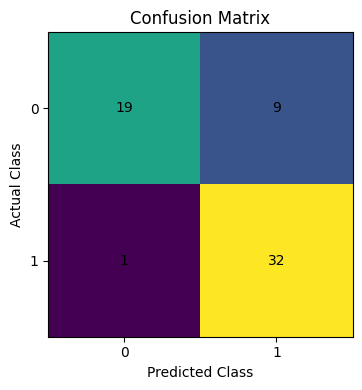

In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

performance = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

display(performance.round(4))

print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0, 1])
plt.yticks([0, 1])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [9]:
rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "RF Importance": model.feature_importances_
})

perm_result = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": feature_names,
    "Permutation Importance": perm_result.importances_mean
})

global_findings = rf_importance.merge(
    permutation_df,
    on="Feature"
)

global_findings = global_findings.sort_values(
    "RF Importance",
    ascending=False
)

global_findings["RF Rank"] = (
    global_findings["RF Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

display(global_findings.round(4))

,Feature,RF Importance,Permutation Importance,RF Rank
2,cp,0.1574,0.0426,1
7,thalach,0.1175,0.0230,2
9,oldpeak,0.1134,0.0131,3
12,thal,0.1071,0.0230,4
4,chol,0.0871,-0.0066,5
11,ca,0.0861,0.0754,6
0,age,0.0778,0.0000,7
3,trestbps,0.0741,0.0098,8
10,slope,0.0595,0.0033,9
8,exang,0.0577,0.0164,10


,Feature,Mean Absolute SHAP
2,cp,0.1093
12,thal,0.0856
11,ca,0.0748
9,oldpeak,0.0605
7,thalach,0.0590
10,slope,0.0476
8,exang,0.0439
1,sex,0.0325
4,chol,0.0302
0,age,0.0261


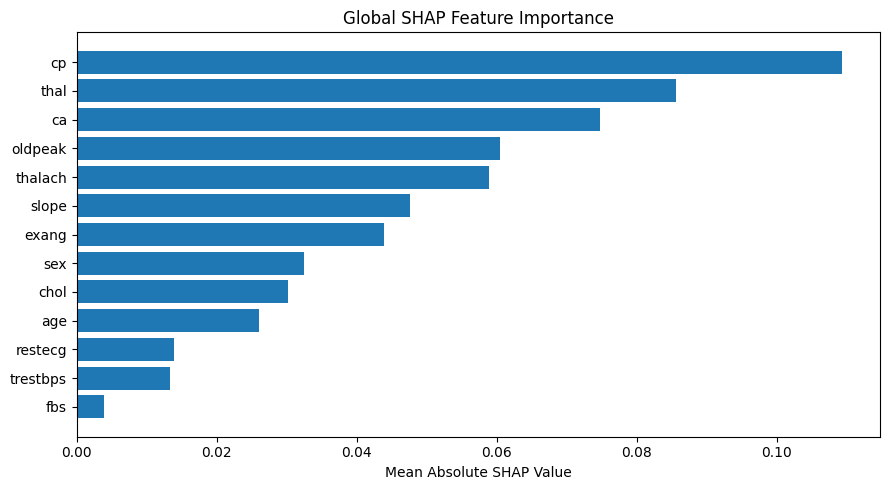

In [10]:
explainer = shap.TreeExplainer(model)

shap_raw = explainer.shap_values(X_test)

class_index = list(model.classes_).index(1)

if isinstance(shap_raw, list):
    shap_class_values = np.asarray(shap_raw[class_index])
else:
    shap_raw = np.asarray(shap_raw)

    if shap_raw.ndim == 3:
        if shap_raw.shape[1] == len(feature_names):
            shap_class_values = shap_raw[:, :, class_index]
        elif shap_raw.shape[2] == len(feature_names):
            shap_class_values = shap_raw[:, class_index, :]
        else:
            raise ValueError("Unexpected SHAP output shape.")
    else:
        shap_class_values = shap_raw

global_shap = np.abs(shap_class_values).mean(axis=0)

shap_global_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": global_shap
})

shap_global_df = shap_global_df.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

display(shap_global_df.round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    shap_global_df["Feature"][::-1],
    shap_global_df["Mean Absolute SHAP"][::-1]
)
plt.title("Global SHAP Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.tight_layout()
plt.show()

In [11]:
patient = X_test.iloc[[0]]

actual_class = int(y_test.loc[patient.index[0]])
predicted_class = int(model.predict(patient)[0])

class_1_index = list(model.classes_).index(1)

probability = model.predict_proba(patient)[0, class_1_index]

local_values = shap_class_values[0]

local_findings = pd.DataFrame({
    "Feature": feature_names,
    "Patient Value": patient.iloc[0].to_numpy(),
    "SHAP Contribution": local_values
})

local_findings["Absolute Contribution"] = (
    local_findings["SHAP Contribution"].abs()
)

local_findings = local_findings.sort_values(
    "Absolute Contribution",
    ascending=False
)

print("Actual Class:", actual_class)
print("Predicted Class:", predicted_class)
print("Probability for Class 1:", round(probability, 4))

display(patient)
display(local_findings.round(4))

Actual Class: 0
Predicted Class: 0
Probability for Class 1: 0.18


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
179,57,1,0,150,276,0,0,112,1,0.6,1,1,1


,Feature,Patient Value,SHAP Contribution,Absolute Contribution
7,thalach,112.0,-0.0896,0.0896
2,cp,0.0,-0.0890,0.0890
11,ca,1.0,-0.0870,0.0870
9,oldpeak,0.6,0.0738,0.0738
10,slope,1.0,-0.0536,0.0536
4,chol,276.0,-0.0446,0.0446
8,exang,1.0,-0.0437,0.0437
12,thal,1.0,0.0380,0.0380
1,sex,1.0,-0.0325,0.0325
0,age,57.0,-0.0221,0.0221


In [12]:
global_local = shap_global_df.merge(
    local_findings,
    on="Feature"
)

global_local["Global Rank"] = (
    global_local["Mean Absolute SHAP"]
    .rank(ascending=False, method="min")
    .astype(int)
)

global_local["Local Rank"] = (
    global_local["Absolute Contribution"]
    .rank(ascending=False, method="min")
    .astype(int)
)

global_local = global_local.sort_values("Global Rank")

display(global_local.round(4))

global_top5 = set(
    global_local.nsmallest(5, "Global Rank")["Feature"]
)

local_top5 = set(
    global_local.nsmallest(5, "Local Rank")["Feature"]
)

print("Top 5 Global Features:", sorted(global_top5))
print("Top 5 Local Features:", sorted(local_top5))
print("Common Features:", sorted(global_top5 & local_top5))

,Feature,Mean Absolute SHAP,Patient Value,SHAP Contribution,Absolute Contribution,Global Rank,Local Rank
0,cp,0.1093,0.0,-0.0890,0.0890,1,2
1,thal,0.0856,1.0,0.0380,0.0380,2,8
2,ca,0.0748,1.0,-0.0870,0.0870,3,3
3,oldpeak,0.0605,0.6,0.0738,0.0738,4,4
4,thalach,0.0590,112.0,-0.0896,0.0896,5,1
5,slope,0.0476,1.0,-0.0536,0.0536,6,5
6,exang,0.0439,1.0,-0.0437,0.0437,7,7
7,sex,0.0325,1.0,-0.0325,0.0325,8,9
8,chol,0.0302,276.0,-0.0446,0.0446,9,6
9,age,0.0261,57.0,-0.0221,0.0221,10,10


Top 5 Global Features: ['ca', 'cp', 'oldpeak', 'thal', 'thalach']
Top 5 Local Features: ['ca', 'cp', 'oldpeak', 'slope', 'thalach']
Common Features: ['ca', 'cp', 'oldpeak', 'thalach']


In [13]:
expert_review = pd.DataFrame({
    "Question": [
        "Are the important features clinically relevant?",
        "Are categorical values correctly interpreted?",
        "Are any important medical variables missing?",
        "Could correlated features affect importance scores?",
        "Is the explanation understandable to doctors?",
        "Could patients misunderstand the explanation?",
        "What additional validation is required?"
    ],
    "Status": ["Pending"] * 7,
    "Comments": [""] * 7
})

display(expert_review)

,Question,Status,Comments
0,Are the important features clinically relevant?,Pending,
1,Are categorical values correctly interpreted?,Pending,
2,Are any important medical variables missing?,Pending,
3,Could correlated features affect importance sc...,Pending,
4,Is the explanation understandable to doctors?,Pending,
5,Could patients misunderstand the explanation?,Pending,
6,What additional validation is required?,Pending,


In [14]:
improvements = pd.DataFrame({
    "Limitation": [
        "Importance does not prove causation",
        "Correlated features may share importance",
        "Local explanations may vary",
        "Dataset may not represent all populations",
        "Single test split has limitations",
        "Categorical encoding may be misunderstood",
        "Predicted probabilities may be uncalibrated"
    ],
    "Proposed Improvement": [
        "Clearly distinguish association from causation",
        "Check feature correlations and grouped importance",
        "Test explanations across repeated runs",
        "Validate on external datasets and patient subgroups",
        "Use cross-validation and report uncertainty",
        "Verify feature definitions with domain experts",
        "Evaluate calibration using suitable metrics"
    ]
})

display(improvements)

,Limitation,Proposed Improvement
0,Importance does not prove causation,Clearly distinguish association from causation
1,Correlated features may share importance,Check feature correlations and grouped importance
2,Local explanations may vary,Test explanations across repeated runs
3,Dataset may not represent all populations,Validate on external datasets and patient subg...
4,Single test split has limitations,Use cross-validation and report uncertainty
5,Categorical encoding may be misunderstood,Verify feature definitions with domain experts
6,Predicted probabilities may be uncalibrated,Evaluate calibration using suitable metrics


In [15]:
top_global = shap_global_df.head(5)["Feature"].tolist()
top_local = local_findings.head(5)["Feature"].tolist()
common = sorted(global_top5 & local_top5)

report = f"""
MODEL INTERPRETABILITY CASE STUDY
Heart Disease Classification

1. OBJECTIVE

To study model interpretability using performance evaluation,
Random Forest feature importance, permutation importance, and SHAP.

2. DATASET AND MODEL

Total observations: {len(df)}
Number of input features: {len(feature_names)}
Training observations: {len(X_train)}
Testing observations: {len(X_test)}
Model: Random Forest Classifier

3. MODEL PERFORMANCE

Accuracy: {accuracy:.4f}
Precision: {precision:.4f}
Recall: {recall:.4f}
F1 Score: {f1:.4f}

These metrics describe performance on the selected test split.
They do not establish clinical readiness.

4. GLOBAL INTERPRETABILITY

Top five SHAP features:
{", ".join(top_global)}

Global importance summarizes model behaviour across test observations.
Permutation importance measures the effect of shuffling features on
test accuracy. Both methods have limitations.

5. LOCAL CASE STUDY

Selected test record: {patient.index[0]}
Actual class: {actual_class}
Predicted class: {predicted_class}
Probability for class 1: {probability:.4f}

Top five local SHAP features:
{", ".join(top_local)}

Features common to global and local top-five lists:
{", ".join(common) if common else "None"}

This is a model explanation, not a medical diagnosis.

6. DOMAIN EXPERT REVIEW

Status: Pending.

A qualified medical professional should review clinical relevance,
feature encoding, missing variables, clarity, and potential risks.
No actual expert feedback is claimed in this report.

7. LIMITATIONS

Feature importance does not prove causation.
Correlated features can affect attribution.
Local explanations may vary across observations.
The dataset may not represent every patient population.
A single test split provides limited evidence of generalization.
Probability calibration and categorical encoding need validation.

8. PROPOSED IMPROVEMENTS

Use cross-validation and external validation data.
Evaluate model performance across relevant patient subgroups.
Check explanation stability across repeated runs.
Validate explanations with qualified medical professionals.
Assess probability calibration.
Document model versions and feature definitions.
Keep clinical decisions under qualified professional oversight.

9. CONCLUSION

Global and local explanations provide complementary views of model
behaviour. Agreement between interpretability methods does not prove
that an explanation is correct or clinically meaningful. Domain review,
external validation, and further reliability testing are necessary
before any real-world clinical use.
"""

with open(
    "model_interpretability_case_study.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print(report)
print("Report saved successfully.")


MODEL INTERPRETABILITY CASE STUDY
Heart Disease Classification

1. OBJECTIVE

To study model interpretability using performance evaluation,
Random Forest feature importance, permutation importance, and SHAP.

2. DATASET AND MODEL

Total observations: 303
Number of input features: 13
Training observations: 242
Testing observations: 61
Model: Random Forest Classifier

3. MODEL PERFORMANCE

Accuracy: 0.8361
Precision: 0.7805
Recall: 0.9697
F1 Score: 0.8649

These metrics describe performance on the selected test split.
They do not establish clinical readiness.

4. GLOBAL INTERPRETABILITY

Top five SHAP features:
cp, thal, ca, oldpeak, thalach

Global importance summarizes model behaviour across test observations.
Permutation importance measures the effect of shuffling features on
test accuracy. Both methods have limitations.

5. LOCAL CASE STUDY

Selected test record: 179
Actual class: 0
Predicted class: 0
Probability for class 1: 0.1800

Top five local SHAP features:
thalach, cp, ca, ol

In [16]:
print("MODEL INTERPRETABILITY SUMMARY")
print("-" * 35)

print("Model Accuracy:", round(accuracy, 4))
print("Top Global Features:", top_global)
print("Top Local Features:", top_local)
print("Common Features:", common)
print("Expert Review: Pending")
print("Report: model_interpretability_case_study.txt")

MODEL INTERPRETABILITY SUMMARY
-----------------------------------
Model Accuracy: 0.8361
Top Global Features: ['cp', 'thal', 'ca', 'oldpeak', 'thalach']
Top Local Features: ['thalach', 'cp', 'ca', 'oldpeak', 'slope']
Common Features: ['ca', 'cp', 'oldpeak', 'thalach']
Expert Review: Pending
Report: model_interpretability_case_study.txt
